**INTRODUCCIÓN**

En este trabajo se estudió el comportamiento en frecuencia de senoidales de diferentes frecuencias, una donde esta concidia con un múltiplo exacto de la resolución espectral, y otras dos donde esta caia entre medio de bines de la DFT. Como al calcular la DFT de una señal se asume periodicidad, para esto se requiere que la señal complete un número entero de ciclos en el tiempo de muestreo. Además, se puede asumir, que una señal senoidal discreta de longitud finita es una senoidal discreta infinita multiplicada por una ventana temporal, donde, de no ser especificado, es una ventana rectangular. Teniendo en cuenta que la DTFT de un pulso rectangular es una sinc periódca (nucleo de Dirichlet) de la forma $N \frac{\operatorname{sinc}(\omega N / 2)}{\operatorname{sinc}(\omega / 2)}$, mientras que la DTFT de una senoidal son dos deltas ubicadas en ω0 y −ω0, entonces la DTFT de una senoidal ventaneada será la convolución de las DTFT de cada una. Por su parte la DFT será el muestreo de la DTFT.

Cuando la frecuencia de la señal coincide exactamente con un bin de la DFT, los lóbulos laterales del núcleo de Dirichlet caen justo sobre los ceros del muestreo espectral, y toda la energía se concentra en un único bin. Pero, si se desintoniza la frecuencia respecto a $\Delta f$ para que los ceros del muestreo dejen de coincidir con los ceros del núcleo de Dirichlet, y los lóbulos laterales se vuelvan visibles dando lugar al desparramo espectral. Además, si la frecuencia cae entre dos bins, las muestras discretas de la DFT caen a los lados del pico real. Esto provoca que el pico registrado en la DFT tenga una amplitud menor a la real.

Para reducir estos efectos se utiliza el el cero padding, que consiste en agregar ceros al final de la señal antes de calcular la DFT. Esto reduce el $\Delta f$, permitiendo interpolar el espectro en más puntos y así visualizar con mayor detalle el lóbulo espectral ya determinado por las N muestras originales. En este trabajo se utilizo esta técnica para comparar la DFT de la señal con y sin cero padding, añadiendose una secuencia de 9*N ceros al final de la señal original.

Además se verificó la conservación de la potencia entre dominios temporal y frecuencial mediante la identidad de Parseval.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

#variables de muestreo
fs  = 1000 # Hz
N   = 1000 # muestras
n=np.arange(N)

#variables de la señal
vmax=np.sqrt(2)
K=[N/4, N/4+0.25, N/4+0.5]

n=np.arange(0,N)
xsen=[]
xsen0pad=[]
potencias=[]
potencias0pad=[]

for k in K:
    sen0pad=[]
    sen0pad=np.pad(vmax*np.sin(k*2*np.pi*n/N), (0, 9*N), mode='constant', constant_values=0)
    xsen.append(vmax*np.sin(k*2*np.pi*n/N))
    xsen0pad.append(sen0pad)
    potencias.append(np.sum((vmax*np.sin(k*2*np.pi*n/N))**2)/N)
    potencias0pad.append(np.sum(sen0pad**2)/N)

**PROCEDIMIENTO**

Se definieron las variables, incluyendo el vector K compuesto por los índices de la frecuencia de la señal y los vectores vacios para las senoidales con y sin cero padding y sus respectivas frecuencias. Luego, utilizando un bucle for, se calcularon las senoidales y sus potencias para cada k, donde las potencias se calcularon como: $\sum_{n=0}^{N-1} |x[n]|^2$

Luego se calcularon las DFT para cada caso y analogamente al caso anterior las potencias con $\frac{1}{N} \sum_{k=0}^{N-1} |X[k]|^2$

Posteriormente se imprimieron estos resultados en una tabla, con el fin de comprobar para cada k la identidad de Parseval. Además se realizaron los graficos para cada k con y sin cero padding, junto a un grafico de la DFT de la senoidal para cada k para poder comparar la amplitud de esta entre los tres casos

In [2]:

#ffts
FF=np.arange(N*fs/N)
FF0pad= np.arange(N*10)*fs/(N*10) #vector de frecuencias

fftsen=(np.fft.fft(xsen, axis=1).T)/N
magsen = np.abs(fftsen)

fftsen0pad=(np.fft.fft(xsen0pad, axis=1).T)/N
magsen0pad = np.abs(fftsen0pad)

potenciasF=[]
potenciasF0pad=[]
for i in range(3):
    energiafrec = np.sum(np.abs(fftsen.T[i]*N)**2) /N
    potenciasF.append(energiafrec / N)
    energiafrec0pad = np.sum(np.abs(fftsen0pad.T[i]*N)**2) /(10*N)
    potenciasF0pad.append(energiafrec0pad / N)
    

Potencias para la senoidal sin 0 padding:
  K       | DOMINIO TEMPORAL| DOMINIO DE FRECUENCIAS
250.0     |      1.000      |     1.000
250.25    |      0.999      |     0.999
250.5     |      1.000      |     1.000 

Potencias para la senoidal con 0 padding:
  K       | DOMINIO TEMPORAL| DOMINIO DE FRECUENCIAS
250.0     |      1.000      |     1.000
250.25    |      0.999      |     0.999
250.5     |      1.000      |     1.000


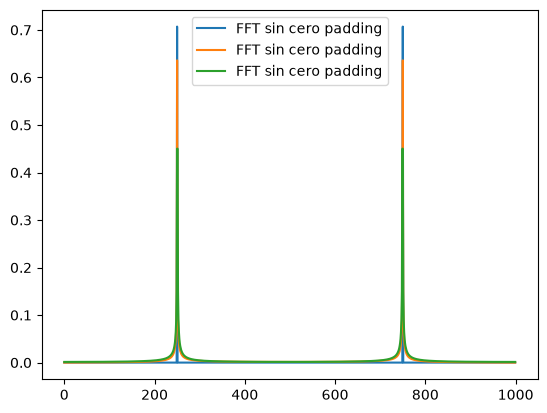

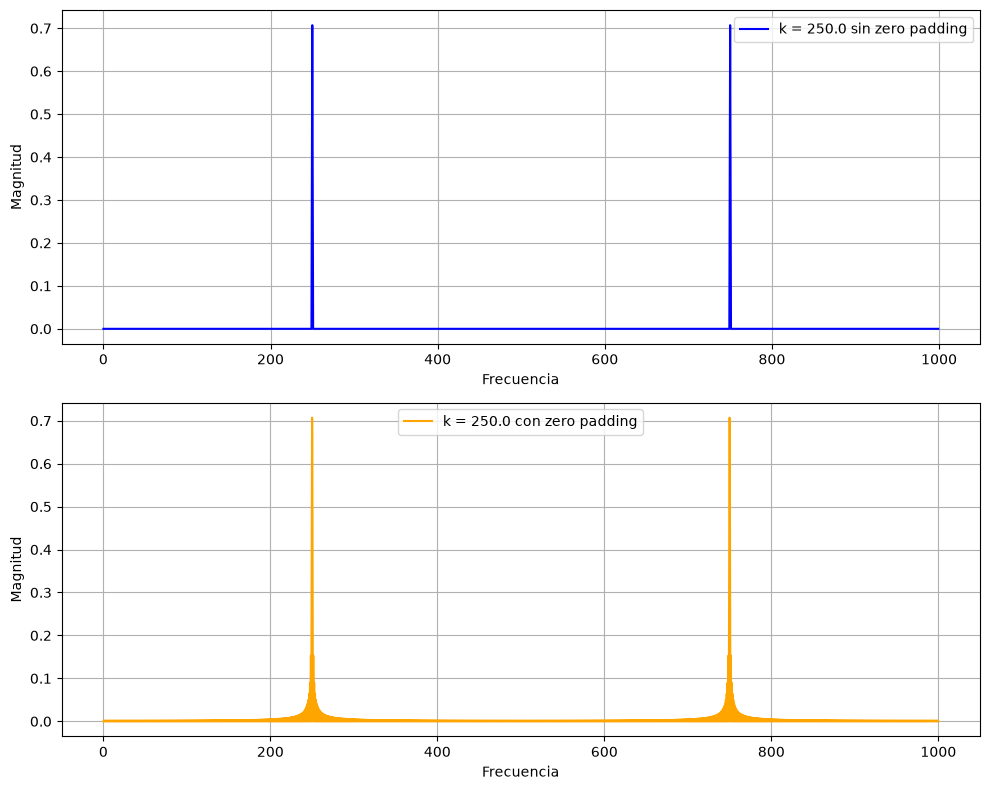

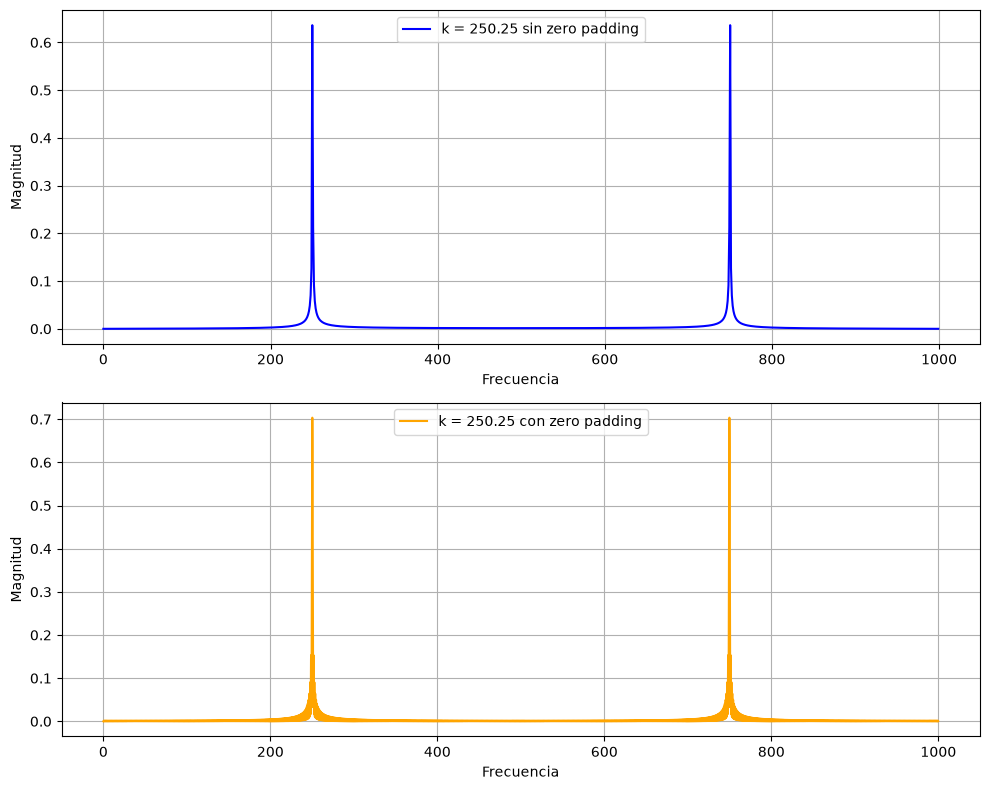

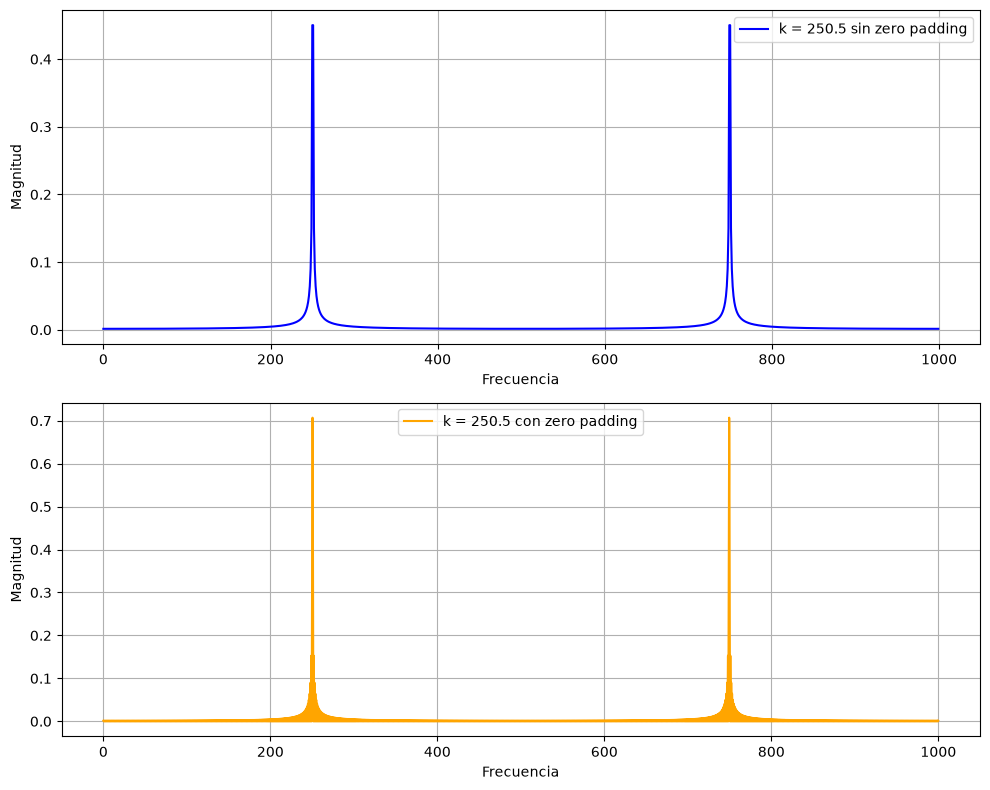

In [3]:
print("Potencias para la senoidal sin 0 padding:\n  K       | DOMINIO TEMPORAL| DOMINIO DE FRECUENCIAS" )
print(f"{K[0]}     |      {potencias[0]:.3f}      |     {potenciasF[0]:.3f}")
print(f"{K[1]}    |      {potencias[1]:.3f}      |     {potenciasF[1]:.3f}")
print(f"{K[2]}     |      {potencias[2]:.3f}      |     {potenciasF[2]:.3f} \n")

print("Potencias para la senoidal con 0 padding:\n  K       | DOMINIO TEMPORAL| DOMINIO DE FRECUENCIAS" )
print(f"{K[0]}     |      {potencias0pad[0]:.3f}      |     {potenciasF0pad[0]:.3f}")
print(f"{K[1]}    |      {potencias0pad[1]:.3f}      |     {potenciasF0pad[1]:.3f}")
print(f"{K[2]}     |      {potencias0pad[2]:.3f}      |     {potenciasF0pad[2]:.3f}")



plt.figure()
plt.plot(FF, magsen, label="FFT sin cero padding")
plt.legend()
plt.show()

plt.figure(figsize=(10, 8))

plt.subplot(2, 1, 1)
plt.plot(FF, magsen.T[0], color='blue', label=f'k = {K[0]} sin zero padding')
plt.legend()
plt.grid()
plt.xlabel("Frecuencia")
plt.ylabel("Magnitud")

plt.subplot(2, 1, 2)
plt.plot(FF0pad, magsen0pad.T[0], color='orange', label=f'k = {K[0]} con zero padding')
plt.legend()
plt.grid()
plt.xlabel("Frecuencia")
plt.ylabel("Magnitud")

plt.tight_layout()
plt.show()



plt.figure(figsize=(10, 8))

plt.subplot(2, 1, 1)
plt.plot(FF, magsen.T[1], color='blue', label=f'k = {K[1]} sin zero padding')
plt.legend()
plt.grid()
plt.xlabel("Frecuencia")
plt.ylabel("Magnitud")

plt.subplot(2, 1, 2)
plt.plot(FF0pad, magsen0pad.T[1], color='orange', label=f'k = {K[1]} con zero padding')
plt.legend()
plt.grid()
plt.xlabel("Frecuencia")
plt.ylabel("Magnitud")

plt.tight_layout()
plt.show()


plt.figure(figsize=(10, 8))

plt.subplot(2, 1, 1)
plt.plot(FF, magsen.T[2], color='blue', label=f'k = {K[2]} sin zero padding')
plt.legend()
plt.grid()
plt.xlabel("Frecuencia")
plt.ylabel("Magnitud")

plt.subplot(2, 1, 2)
plt.plot(FF0pad, magsen0pad.T[2], color='orange', label=f'k = {K[2]} con zero padding')
plt.legend()
plt.grid()
plt.xlabel("Frecuencia")
plt.ylabel("Magnitud")

plt.tight_layout()
plt.show()

**ANÁLISIS DE LOS RESULTADOS**

Al evaluar y comparar lo que pasa para los 3 valores de k considerados se puede ver graficamente que cuando w0=250Hz la señal completa exactamente 250 ciclos en la ventana de N muestras con periodicidad perfecta. Por esto, el espectro que se observa concentra su energía en un único bin, con amplitud $\frac{\sqrt{2}}{2}$, la mitad de la amplitud de vmax. En cambio, para w0 = 250.25 Hz y w0 = 250.5Hz, al desintonizar la frecuencia, la señal ya no completa un número entero de ciclos dentro de la ventana. Como w0 ya no cae en un bin exacto de la DFT, lo cual provoca que la energía se dispersa a bins adyacentes, por lo cual se puede ver un ensanchamiento en la base del pico para estos casos. Además el bin más cercano a la frecuencia real no coincide con el máximo del lobulo principal, provocando un pico de menor altura (aproximadamente 0.63 para 250.25Hz y 0.45 para 250.5 Hz)

Usando la identidad de Parseval, se verificó que la potencia se conserva entre dominios para los tres casos como se muestra en la tabla. Esto demuestra que el desparramo espectral no influye en la potencia de la DFT, ya que solo redistribuye la energía, no la disminuye ni aumenta.

Por último, evaluando las señales con cero padding de 9*N, se puede observar que, para los casos de w0 = 250.25 Hz y w0 = 250.5Hz la amplitud del pico sube a $\frac{\sqrt{2}}{2}$, esto se debe a que con $\Delta f$ más fino, aumenta la resolución espectral, permitiendo interpolar frecuancias mas altas, es decir, el bin más cercano queda más cerca al máximo real del lóbulo principal. Precisamente 250.5 Hz cae exactamente sobre uno de los nuevos bins. Este aumento de la amplitud no redujo el desparramo, ya que este depende de señal y la ventana, no de cuántos puntos de frecuencia se calculan

**CONCLUSIÓN**

Con los resultados obtenidos se pudo in¿dentifica el desparramo espectral como consecuencia del ventaneo de la señal. Cuando la frecuencia de la señal coincide con un múltiplo entero de $\Delta f$, los ceros del núcleo de Dirichlet caen exactamente sobre los bins muestreados por la DFT, ocultando los lóbulos laterales, pero, si se desintoniza la frecuencia de la señal, ya no coincide en un bin exacto y la energía se dispersa visiblemente entre bins vecinos.Sin embargo, por la identidad de Parseval se vió que esta dispersión es una redistribución. ya que la potencia total de la señal permanece estable entre el dominio temporal y el frecuencial.

En ese sentido, se utilizó el cero padding para reducir esta disminución en la amplitud máxima de la DFT, ya que al reducir $\Delta f$, permite que la el muestreo se acerque más al máximo real del lóbulo principal. Sin embargo, se pudo ver que el cero padding no reduce el desparramo espectral en sí ni agrega información nueva, sólo interpola con mayor densidad un espectro ya dado por las N muestras originales. 